# 09-cluster — Phân cụm pool ở bước 09: kiểm, code, landscape không nhãn

**Câu hỏi**: bước 09 làm gì, và nghiệm k-means mà pipeline giữ ổn định đến đâu theo khởi tạo, theo thứ tự hàng và theo seed, khi không đọc nhãn? (Q09.12 phần không nhãn, Q09.13 phần không nhãn; QD26)

**Không nhãn**: notebook không đọc nhãn lớp hay vai trò ảnh; chỉ đọc đặc trưng pool, đầu ra của bước 09, và camera, cuộn từ tên file. Phần dùng nhãn ở `09d-ownership`, sau tiền đăng ký E09.07 (`1ce3233`).

### Nguồn gốc (provenance)

In commit và trạng thái dirty của code, rồi đặt `XLA_FLAGS` trước mọi lần import jax (mẫu ở `lab/README.vi.md` §11). Kiểm thêm phiên bản scikit-learn, vì phép tách ở 1.2 và luật giữ nghiệm theo đúng code của bản 1.5.2, và kiểm commit tiền đăng ký E09.07 đã có trong lịch sử (QD26).

In [1]:
# cell 0: provenance (run first)
import os, subprocess, sys
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / "main.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT); sys.path[:0] = [str(ROOT), str(ROOT / "lab")]
import replay; os.environ["XLA_FLAGS"] = replay._xla_flags()   # GPU deterministic mode before any jax import
git = lambda *a: subprocess.run(["git", *a], capture_output=True, text=True).stdout.strip()
print("commit", git("rev-parse", "--short", "HEAD"),
      "| code dirty", bool(git("status", "--porcelain", "--", ".", ":(exclude)runs", ":(exclude)notes",
                               ":(exclude)lab/*.ipynb", ":(exclude)lab/*.md")),
      "| XLA_FLAGS", os.environ["XLA_FLAGS"])
import sklearn
print("scikit-learn", sklearn.__version__,
      "| E09.07 pre-registration 1ce3233 is an ancestor of HEAD:",
      subprocess.run(["git", "merge-base", "--is-ancestor", "1ce3233", "HEAD"]).returncode == 0)
assert sklearn.__version__ == "1.5.2", "landscape.decompose and keep_rule follow scikit-learn 1.5.2"

commit 62f81a8 | code dirty False | XLA_FLAGS --xla_gpu_deterministic_ops=true
scikit-learn 1.5.2 | E09.07 pre-registration 1ce3233 is an ancestor of HEAD: True


- **Kết quả**: commit `cf2dc53`, code dirty False, XLA_FLAGS `--xla_gpu_deterministic_ops=true`; scikit-learn 1.5.2; commit tiền đăng ký E09.07 `1ce3233` có trong lịch sử của HEAD.

## 1. Kiểm

### 1.1 Chạy lại bước 09

Dùng `replay.rerun`: nạp ảnh chụp sau bước 08 của `gc10_v2_ft_r0_s4`, đặt RNG toàn cục về `rng_in` của bước 09, chạy lại `s09_cluster`, rồi so ba khoá với `snap/09.pkl`:
- `ids`: id cụm của 748 ảnh pool;
- `cluster`: mô hình k-means (so tâm cụm);
- `inertia`.

Quy tắc đạt như mọi bước (QD21/C1): khoá rời rạc trùng tuyệt đối; số thực lệch ≤ 1e-6 × max|giá trị|; tâm cụm lệch trong mức `np.allclose(rtol=1e-6, atol=1e-6)`, vì tổng OpenMP có thể lệch ở mức ULP.

Dự đoán: 3/3 khoá đạt; inertia 82926.203, trùng khoá `k5_inertia` của `gc10_e09_05_v2_r0_s4`.

In [2]:
# cell 1: rerun step 09 of r0 s4 from the snapshot of step 08 and compare with snap/09.pkl
import numpy as np
RUN = "gc10_v2_ft_r0_s4"
out_11, ok_11 = replay.rerun(RUN, "09")
print("inertia:", out_11["inertia"], "| cluster sizes:", np.bincount(out_11["ids"]).tolist())

/home/rito/miniforge3/envs/vbcgcd/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


rerun step 09 of gc10_v2_ft_r0_s4 | device gpu | GPU now NVIDIA GeForce RTX 4060 Laptop GPU, 621.01 | GPU of the run NVIDIA GeForce RTX 4060 Laptop GPU, 617.42 | driver differs: float outputs may move in the last bits
(array([5, 6, 7, 8, 9], dtype=int32), array([ 95, 157, 272, 121, 103]))
  OK   ids          array int32            max|diff| 0
  OK   cluster      KMeansCluster          max|diff| nan
  OK   inertia      float                  max|diff| 0
rerun step 09: OK (3/3 keys)
inertia: 82926.203125 | cluster sizes: [95, 157, 272, 121, 103]


- **Kết quả**:
  - `rerun` bước 09 đạt 3/3 khoá: `ids` và `inertia` trùng hẳn với ảnh chụp (max|diff| = 0), `cluster` trùng tâm cụm. Driver GPU đã đổi từ 617.42 sang 621.01, nhưng bước 09 chạy trên CPU nên không bị ảnh hưởng.
  - inertia 82926.203125; cỡ 5 cụm: 95, 157, 272, 121, 103 (id cụm in ra là 5–9 vì `main.py` cộng thêm offset 5).
- **Ý nghĩa**: đúng như dự đoán. Bước 09 tái lập được từ `rng_in`, và inertia trùng khoá `k5_inertia` của E09.05 v2.

### 1.2 Tách `n_init` 10 thành 10 lần khởi tạo đơn

Bước 09 gọi `KMeans(n_clusters=5, n_init=10, random_state=None)` của scikit-learn. Với `random_state=None`, `check_random_state` trả về RNG toàn cục, và vòng `for i in range(self._n_init)` lấy số tiếp từ đúng luồng đó cho mỗi lần khởi tạo k-means++. Nghiệm được giữ thay nghiệm cũ khi inertia nhỏ hơn hẳn và phân hoạch khác (`_is_same_clustering`).

Nếu lập luận này đúng, 10 lần `KMeans(n_init=1)` liên tiếp, xuất phát từ `rng_in` của bước 09, phải cho lại đúng nghiệm của pipeline khi áp cùng luật giữ nghiệm. Đây là nền cho mọi phép đo ở mục 3: nó cho biết pipeline đã chọn lần khởi tạo nào trong 10, và chín lần kia ra sao. Đã thử trên dữ liệu đồ chơi (QD26); ở đây làm trên dữ liệu thật, cả 15 ảnh chụp.

**Cách làm**: `landscape.decompose(run)` cho mỗi ảnh chụp. Bốn phép kiểm:
- nghiệm được giữ trùng `KMeans(n_init=10)` chạy lại từ cùng trạng thái;
- trùng `ids` của pipeline (so sau khi đánh lại số cụm theo thứ tự xuất hiện);
- inertia lệch tương đối ≤ 1e-6;
- trạng thái RNG sau 10 lần chạy trùng trạng thái sau `n_init=10`.

Kèm theo: lần khởi tạo được giữ, số phân hoạch khác nhau trong 10 lần, inertia nhỏ nhất và lớn nhất.

Dự đoán:
- 15/15 đạt cả bốn phép kiểm;
- inertia của pipeline trùng khoá `k5_inertia` của E09.05 v2 (r0: 82352.2, 82649.4, 83112.6, 82477.7, 82926.2);
- [SUY LUẬN] mỗi ảnh chụp có 5–10 phân hoạch khác nhau trong 10 lần; lần được giữ rải khắp 0–9; inertia của 10 lần trải khoảng 1–2%.

In [3]:
# cell 2: the pipeline's KMeans(n_init=10) replayed as 10 single inits from rng_in of step 09, 15 snapshots
import pandas as pd
import landscape as ls
RUNS = [f"gc10_v2_ft_r{r}_s{s}" for r in range(3) for s in range(5)]

def same_state_12(a, b):                       # numpy RNG state: (name, keys, pos, has_gauss, cached_gaussian)
    return a[0] == b[0] and np.array_equal(a[1], b[1]) and tuple(a[2:]) == tuple(b[2:])

rows_12 = []
for run in RUNS:
    d = ls.decompose(run)
    k = d["kept"]
    rows_12.append(dict(
        run=run.replace("gc10_v2_ft_", ""), kept=k,
        same_n_init10=bool(np.array_equal(d["labels"][k], d["full_labels"])),
        same_pipeline=bool(np.array_equal(d["labels"][k], d["pipeline"])),
        inertia_rel_diff=abs(d["inertias"][k] - d["pipeline_inertia"]) / d["pipeline_inertia"],
        rng_after_equal=same_state_12(d["after"], d["full_after"]),
        n_distinct=len({l.tobytes() for l in d["labels"]}),
        inertia_pipeline=d["pipeline_inertia"], inertia_min=d["inertias"].min(), inertia_max=d["inertias"].max()))
df_12 = pd.DataFrame(rows_12)
df_12["spread_pct"] = 100 * (df_12.inertia_max - df_12.inertia_min) / df_12.inertia_min
print(df_12.to_string(index=False, float_format=lambda v: f"{v:.6g}"))
ok_12 = df_12.same_n_init10 & df_12.same_pipeline & (df_12.inertia_rel_diff <= 1e-6) & df_12.rng_after_equal
print("all four checks:", int(ok_12.sum()), "/ 15")

  run  kept  same_n_init10  same_pipeline  inertia_rel_diff  rng_after_equal  n_distinct  inertia_pipeline  inertia_min  inertia_max  spread_pct
r0_s0     5           True           True       9.48669e-08             True          10           82352.2      82352.2      83777.3     1.73048
r0_s1     8           True           True                 0             True          10           82649.4      82649.4      84800.3     2.60247
r0_s2     7           True           True       9.39989e-08             True          10           83112.7      83112.7        84446     1.60432
r0_s3     7           True           True                 0             True          10           82477.7      82477.7      83834.2     1.64469
r0_s4     0           True           True                 0             True          10           82926.2      82926.2      84613.8     2.03505
r1_s0     3           True           True                 0             True          10           89441.9      89441.9      92275

- **Kết quả**:
  - Cả 15/15 ảnh chụp đạt bốn phép kiểm: nghiệm được giữ trùng `n_init` 10, trùng `ids` của pipeline, trạng thái RNG sau 10 lần chạy trùng.
  - inertia lệch tương đối tối đa 1.7e-7, do thứ tự cộng OpenMP khác nhau; inertia của pipeline trùng khoá `k5_inertia` của E09.05 v2.
  - Trong 10 lần khởi tạo, 14/15 ảnh chụp cho 10 phân hoạch khác nhau; r1 s3 cho 9.
  - Lần khởi tạo được giữ là: 5, 8, 7, 7, 0 (r0); 3, 6, 1, 6, 4 (r1); 6, 1, 0, 3, 2 (r2).
  - Khoảng trải inertia của 10 lần: r0 1.6–2.6%, r1 2.6–4.0%, r2 2.3–3.5%.
- **Ý nghĩa**:
  - Lập luận ở trên đúng trên dữ liệu thật. Nghiệm của pipeline đúng là lần có inertia nhỏ nhất trong 10 lần khởi tạo đơn nối tiếp nhau trên cùng luồng RNG. Vì vậy landscape ở mục 3 đo đúng thủ tục mà pipeline dùng.
  - Phần dự đoán sai: inertia trải rộng hơn dự đoán 1–2% ở r1 và r2.
  - [SUY LUẬN] Gần như mỗi lần khởi tạo cho một phân hoạch riêng, giống dữ liệu đồ chơi. Nếu landscape cũng như vậy, việc gộp các phân hoạch thành nhóm nghiệm (mode) ở mục 3 sẽ phụ thuộc nhiều vào ngưỡng ARI; đó chính là nhược điểm đã nêu khi duyệt B.

## 2. Code

### 2.1 Bước 09 trong code và trong paper

Mục này in đúng các hàm mà bước 09 chạy: `s09_cluster` của bàn mổ, `KMeansCluster` của repo, và những dòng của `KMeans.fit`, `_kmeans_plusplus` trong scikit-learn 1.5.2 mà phép tách ở 1.2 dựa vào. Kèm theo là các tham số mặc định và đầu vào thật: shape của `pool_x`, K, và ngưỡng hội tụ của Lloyd.

Đối chiếu với paper:
- Alg. 1 dòng 15 ghi ŷᵢ ← clustering(h(xᵢ)): phân cụm chạy trên đặc trưng backbone của toàn bộ dữ liệu không nhãn của phiên, gồm cả ảnh của lớp cũ.
- App. C.3 ghi "standard k-means"; K bằng số lớp mới (ghi chú ở D12).
- Code gốc dùng GMM với `n_init` 1. k-means với `n_init` 10 là thay đổi của fork (D18), chọn dựa trên số đo ở CIFAR-100.

Dự đoán:
- k-means chạy trên đặc trưng thô (748 × 768), không chạy trên PCA-64 mà bộ phân lớp dùng từ bước 05;
- `init="k-means++"`, `algorithm="lloyd"`, `max_iter=300`, `tol=1e-4`;
- k-means++ thử 2 + ⌊ln 5⌋ = 3 ứng viên cho mỗi tâm.

In [4]:
# cell 3: the code of step 09, the lines of scikit-learn 1.5.2 KMeans it relies on, and its real input
import inspect
import clustering.kmeans as ckm
from sklearn.cluster import _kmeans as skm
print(inspect.getsource(replay.s09_cluster))
print(inspect.getsource(ckm.KMeansCluster))
keys_21 = ("check_random_state", "X_mean", "for i in range(self._n_init)", "_init_centroids(", "kmeans_single(",
           "best_inertia is None", "inertia < best_inertia", "_is_same_clustering")
print("\n".join(l for l in inspect.getsource(skm.KMeans.fit).split("\n") if any(s in l for s in keys_21)))
print([l.strip() for l in inspect.getsource(skm._kmeans_plusplus).split("\n")
       if "n_local_trials = " in l or "random_state." in l or "searchsorted" in l])
km_21 = ckm.KMeansCluster(num_classes=5).model
print({k: getattr(km_21, k) for k in ("init", "n_init", "max_iter", "tol", "algorithm", "random_state")})
p_21 = ls.pool(RUN)                                            # label-free inputs of step 09
print("pool_x", p_21["x"].shape, p_21["x"].dtype, "| K", p_21["k"],
      "| Lloyd stops when the center shift^2 <= tol x mean feature variance =", 1e-4 * p_21["x"].var(axis=0).mean())

def s09_cluster(st):
    """09 k-means on the raw pool features (KMeansCluster, n_init = kmeans_n_init; random_state=None draws the
    global RNG). In: pool_x, offset. Out: ids (0..K-1, fit order), cluster (has predict_raw), inertia."""
    import main
    a = st["args"]
    cl = main.Clustering_alg(a.clustering_alg)(num_classes=a.increment, label_offset=st["offset"], n_init=a.kmeans_n_init)
    cl.fit(st["pool_x"])
    ids = cl.predict_raw(st["pool_x"])
    print(np.unique(ids + st["offset"], return_counts=True))         # cluster sizes, as main.py prints them
    return dict(ids=ids, cluster=cl, inertia=float(cl.model.inertia_))

class KMeansCluster(ClusteringBase):

    def __init__(self, num_classes, label_offset=0, random_state=None, n_init=10):
        super().__init__(num_classes, label_offset)

        self.random_state = random_state
        self.n_init = n_init
        self.model = KMeans(n_clusters=num_classes, n_init=n_init, random_state=random_state)

    @override
    de

- **Kết quả**:
  - `s09_cluster` gọi `main.Clustering_alg("kmeans")`, tức `KMeansCluster(num_classes=5, n_init=10)` với `random_state=None`, fit trên `pool_x`; `ids` lấy từ `model.predict(pool_x)`, trùng `labels_` (1.2).
  - Trong `KMeans.fit` của scikit-learn 1.5.2: `check_random_state(self.random_state)`; trừ trung bình đặc trưng (`X -= X_mean`), nên inertia không đổi; một vòng `for i in range(self._n_init)`, mỗi vòng gọi `_init_centroids` rồi `kmeans_single`; nghiệm mới chỉ thay nghiệm cũ khi `inertia < best_inertia` và phân hoạch khác.
  - k-means++: `n_local_trials = 2 + int(np.log(n_clusters))` = 3 ứng viên cho mỗi tâm; tâm đầu chọn bằng `random_state.choice(n_samples, …)` theo chỉ số hàng; các tâm sau chọn bằng `random_state.uniform` rồi `np.searchsorted` trên tổng tích luỹ D², cũng theo thứ tự hàng.
  - Tham số: `init="k-means++"`, `n_init=10`, `max_iter=300`, `tol=1e-4`, `algorithm="lloyd"`, `random_state=None`.
  - Đầu vào: `pool_x` 748 × 768 float32, K = 5. Lloyd dừng khi tổng bình phương độ dịch tâm ≤ 2.18e-5 (= 1e-4 × phương sai trung bình của đặc trưng).
- **Ý nghĩa**:
  - Đúng như dự đoán. Code khớp paper ở chỗ chính: phân cụm chạy trên đặc trưng backbone của toàn bộ dữ liệu không nhãn (Alg. 1 dòng 15), K bằng số lớp mới.
  - Chỗ khác paper đã ghi ở D18: `n_init` 10 là của fork; code gốc dùng GMM với `n_init` 1.
  - Nhãn giả sinh trong không gian 768 chiều thô, còn Gaussian của bộ phân lớp học trong PCA-64 của S0 (bước 05). Hai bước dùng hai hình học khác nhau. [SUY LUẬN] Chỗ lệch này cần nhớ khi đọc 11–13: cụm được tách theo những hướng mà PCA-64 có thể không giữ.
  - Thứ tự hàng đi vào k-means++ ở cả hai chỗ chọn tâm (`choice`, `searchsorted`). Đó là cơ chế của điểm 2 ở QD26; 3.4 sẽ kiểm trên dữ liệu thật.

## 3. Landscape (không nhãn)

### 3.0 Tính landscape cho 15 ảnh chụp

Cell này chỉ tính, rồi ghi cache theo QD26:
- mỗi ảnh chụp 10.000 lần khởi tạo đơn k-means++ (`landscape.singles`), mỗi ảnh chụp một luồng RNG riêng, không dùng `rng_in`;
- ở r0 s4 thêm 1.000 lần chạy `n_init` 10 từ `rng_in` với thứ tự hàng hoán vị ngẫu nhiên (`landscape.permuted`), dùng ở 3.4.

Cache nằm ở `runs/<run>/landscape/` (git bỏ qua); chạy lại cell thì chỉ đọc cache.

Các tiến trình được tạo bằng spawn, không dùng fork: sklearn đã chạy OpenMP trong tiến trình notebook (1.1, 1.2), và fork sau khi OpenMP đã chạy có thể làm tiến trình con treo. Hàm `run_all` của `landscape.py` đang dùng fork; mình sẽ sửa trong lần ghi chép cuối notebook. Cell này tự tạo pool spawn.

Dự đoán [SUY LUẬN]: 20–60 phút, tuỳ số nhân CPU; mỗi ảnh chụp ghi một file khoảng vài MB.

In [5]:
# cell 4: compute (or load) the landscape caches: 10 000 single inits per snapshot, 1 000 permuted pipeline runs on r0 s4
import multiprocessing as mp, time
from concurrent.futures import ProcessPoolExecutor
jobs_30 = [(ls.singles, r, {"n": 10000}) for r in RUNS] + [(ls.permuted, RUN, {"m": 1000})]
W_30 = max(1, (os.cpu_count() or 2) - 2)
t0_30 = time.time()
with ProcessPoolExecutor(max_workers=W_30, mp_context=mp.get_context("spawn")) as ex:
    metas_30 = list(ex.map(ls._job, jobs_30))
print(f"workers {W_30} | wall time {(time.time() - t0_30) / 60:.1f} min")
print(pd.DataFrame([dict(run=r.replace("gc10_v2_ft_", ""), what=m["what"], params=m["params"], seconds=m["seconds"],
                         made=m["made"], sklearn=m["sklearn"]) for r, m in metas_30]).to_string(index=False))

workers 13 | wall time 0.1 min
  run     what       params  seconds             made sklearn
r0_s0  singles {'n': 10000}    602.5 2026-11-04 20:11   1.5.2
r0_s1  singles {'n': 10000}    604.3 2026-11-04 20:11   1.5.2
r0_s2  singles {'n': 10000}    607.7 2026-11-04 20:11   1.5.2
r0_s3  singles {'n': 10000}    592.3 2026-11-04 20:11   1.5.2
r0_s4  singles {'n': 10000}    606.7 2026-11-04 20:11   1.5.2
r1_s0  singles {'n': 10000}    602.7 2026-11-04 20:11   1.5.2
r1_s1  singles {'n': 10000}    603.9 2026-11-04 20:11   1.5.2
r1_s2  singles {'n': 10000}    586.6 2026-11-04 20:11   1.5.2
r1_s3  singles {'n': 10000}    602.1 2026-11-04 20:11   1.5.2
r1_s4  singles {'n': 10000}    598.9 2026-11-04 20:11   1.5.2
r2_s0  singles {'n': 10000}    572.6 2026-11-04 20:11   1.5.2
r2_s1  singles {'n': 10000}    585.9 2026-11-04 20:11   1.5.2
r2_s2  singles {'n': 10000}    590.9 2026-11-04 20:11   1.5.2
r2_s3  singles {'n': 10000}    144.9 2026-11-04 20:13   1.5.2
r2_s4  singles {'n': 10000}    135.1 20

- **Kết quả**: 13 tiến trình song song, tổng thời gian 12.2 phút.
  - 13 ảnh chụp đầu: mỗi ảnh chụp 573–608 s cho 10.000 lần khởi tạo, khoảng 60 ms mỗi lần.
  - r2 s3 và r2 s4 chỉ mất 135–145 s (khoảng 14 ms mỗi lần), vì chạy sau khi các tiến trình khác đã xong.
  - 1.000 lần chạy `n_init` 10 với hàng hoán vị ở r0 s4: 125.5 s.
- **Ý nghĩa**:
  - Nhanh hơn dự đoán (20–60 phút). Thời gian cho mỗi lần khởi tạo chậm đi khoảng 4 lần khi 13 tiến trình dùng chung CPU và bộ nhớ.
  - Cache đã đủ cho 15 ảnh chụp; từ đây mọi cell chỉ đọc cache.

### 3.1 Pipeline đứng ở đâu trong landscape

Với mỗi ảnh chụp, từ 10.000 lần khởi tạo đơn:
- **Cấp phân hoạch** (không cần quy ước nhóm):
  - số phân hoạch khác nhau;
  - nghiệm của pipeline có xuất hiện đúng y hệt trong 10.000 lần không;
  - inertia tốt nhất tìm được; pipeline cách nó bao nhiêu phần trăm;
  - F = tỷ lệ lần khởi tạo đơn có inertia nhỏ hơn hẳn pipeline;
  - P(lần chạy pipeline khác tốt hơn) = 1 − (1 − F)¹⁰, theo thống kê thứ tự của giá trị nhỏ nhất trong 10 lần;
  - ARI giữa nghiệm pipeline và nghiệm tốt nhất;
  - số vòng Lloyd trung vị.
- **Cấp nhóm nghiệm**, ở ba ngưỡng ARI 0.90 / 0.95 / 0.99 (QD26):
  - số nhóm;
  - khối lượng chưa thấy theo Good–Turing;
  - p_best = tần suất của nhóm sâu nhất trong các lần khởi tạo đơn; P10_best = xác suất best-of-10 rơi vào nhóm đó (trọng số `best_of_weights`);
  - tỷ lệ của nhóm đông nhất;
  - nhóm của pipeline: số thứ tự theo độ sâu, 0 là nhóm sâu nhất; −1 nếu không gần nghiệm đầu nhóm nào; kèm ARI lớn nhất với một nghiệm đầu nhóm.

`modes_all` chạy song song; thời gian in ra.

Dự đoán [SUY LUẬN]:
- gần như mỗi lần khởi tạo là một phân hoạch riêng (trên 9.000 phân hoạch khác nhau), vì ở 1.2 thì 149/150 lần khởi tạo cho phân hoạch khác nhau;
- nghiệm của pipeline xuất hiện y hệt 0–vài lần;
- pipeline cách nghiệm tốt nhất 0.2–1.5%; P(lần chạy khác tốt hơn) trong khoảng 0.3–0.9; ARI giữa pipeline và nghiệm tốt nhất 0.6–0.9 (`04-loader`: 0.73);
- số nhóm giảm mạnh từ ngưỡng 0.99 xuống 0.90; nếu ở 0.95 vẫn có hàng nghìn nhóm, kết luận dựa vào các đại lượng cấp phân hoạch, không dựa vào nhóm.

In [6]:
# cell 5: per snapshot: where the pipeline stands among 10 000 single inits; solution modes at three ARI thresholds
TAUS = (0.90, 0.95, 0.99)
t0_31 = time.time()
MD = ls.modes_all(RUNS, n=10000, taus=TAUS, workers=W_30)                 # {(run, tau): modes}
print(f"modes_all: {(time.time() - t0_31) / 60:.1f} min")
rowsA_31, rowsB_31 = [], []
for run in RUNS:
    s, _ = ls.singles(run, n=10000)
    L, J = s["L"], s["J"]
    p = ls.pool(run)
    pipe, Jp = ls.canon(p["ids"]), p["inertia"]
    F = float((J < Jp * (1 - 1e-6)).mean())                              # single inits strictly below the pipeline
    w10 = ls.best_of_weights(J, 10)
    rowsA_31.append(dict(run=run[11:], distinct=len({r.tobytes() for r in L}), pipe_seen=int((L == pipe).all(1).sum()),
                         J_pipe=Jp, J_best=J.min(), gap_pct=100 * (Jp - J.min()) / J.min(), F_single=F,
                         P_better_run=1 - (1 - F) ** 10, ari_pipe_best=ls.ari(pipe, L[J.argmin()]),
                         n_iter_med=float(np.median(s["n_iter"]))))
    for tau in TAUS:
        md = MD[(run, tau)]
        pm, pa = ls.assign(pipe, L, md, tau)
        rowsB_31.append(dict(run=run[11:], tau=tau, modes=len(md["leaders"]), good_turing=ls.good_turing(md["mode"]),
                             p_best=float((md["mode"] == 0).mean()), P10_best=float(w10[md["mode"] == 0].sum()),
                             top_share=float(md["count"].max() / len(J)), pipe_mode=pm, pipe_max_ari=pa))
dfA_31, dfB_31 = pd.DataFrame(rowsA_31), pd.DataFrame(rowsB_31)
print(dfA_31.to_string(index=False, float_format=lambda v: f"{v:.4g}"))
for tau in TAUS:
    print(f"\ntau = {tau}")
    print(dfB_31[dfB_31.tau == tau].drop(columns="tau").to_string(index=False, float_format=lambda v: f"{v:.3g}"))

modes_all: 2.8 min
  run  distinct  pipe_seen    J_pipe    J_best   gap_pct  F_single  P_better_run  ari_pipe_best  n_iter_med
r0_s0      6336        103 8.235e+04 8.227e+04   0.09864      0.04        0.3352         0.9587          12
r0_s1      6005         15 8.265e+04 8.261e+04   0.04866    0.0443        0.3644         0.9254          12
r0_s2      6588          2 8.311e+04 8.268e+04    0.5184     0.258        0.9494         0.6649          12
r0_s3      6855          9 8.248e+04 8.229e+04    0.2301    0.0958        0.6347         0.7427          12
r0_s4      5629         15 8.293e+04 8.274e+04    0.2196    0.0649        0.4888         0.7496          13
r1_s0      4938         10 8.944e+04 8.943e+04   0.01401    0.0461        0.3762         0.9721          12
r1_s1      4834          1 8.976e+04 8.954e+04    0.2452    0.1168        0.7112         0.7955          12
r1_s2      4978          1 8.958e+04 8.956e+04   0.02433    0.0685        0.5082         0.9745          12
r1_s3    

- **Kết quả**: `modes_all` chạy 2.8 phút.
  - **Cấp phân hoạch**:
    - 10.000 lần khởi tạo đơn cho 4658–6855 phân hoạch khác nhau: ít hơn 10.000 nhiều, vì nhiều lần khởi tạo hội tụ về cùng một phân hoạch.
    - Nghiệm của pipeline xuất hiện y hệt 0–211 lần (r2 s4: 211, r2 s2: 140, r0 s0: 103; r1 s4: 0).
    - Lloyd chạy trung vị 11–13 vòng.
    - 15 ảnh chụp chia rõ thành hai nhóm:
      - 8/15 ảnh chụp có nghiệm pipeline gần như trùng nghiệm tốt nhất (ARI 0.93–0.996, cách dưới 0.1%): r0 s0, s1; r1 s0, s2, s3; r2 s1, s2, s4.
      - 7/15 ảnh chụp có nghiệm pipeline xa nghiệm tốt nhất (ARI 0.62–0.80, cách 0.11–0.58%; P(lần chạy pipeline khác cho inertia thấp hơn hẳn) từ 0.49 đến 0.99): r0 s2, s3, s4; r1 s1, s4; r2 s0, s3.
  - **Cấp nhóm nghiệm**:
    - Ngưỡng 0.90: 235–527 nhóm, khối lượng chưa thấy theo Good–Turing 0.007–0.016. Ngưỡng 0.95: 521–1238 nhóm, Good–Turing 0.02–0.055. Ngưỡng 0.99: 2175–4280 nhóm, Good–Turing 0.13–0.30.
    - Ở ngưỡng 0.95, best-of-10 rơi vào nhóm sâu nhất với xác suất 0.11–0.70. FT seed r1 cao nhất (0.48–0.70), r0 thấp nhất (0.17–0.41).
    - Nghiệm pipeline thuộc nhóm sâu nhất ở 8/15 ảnh chụp (ngưỡng 0.90) và 7/15 (ngưỡng 0.95): khớp với hai nhóm ảnh chụp ở trên. Ở ngưỡng 0.99 chỉ còn r2 s2.
- **Ý nghĩa**:
  - Dự đoán sai ở số phân hoạch khác nhau. Landscape có cấu trúc rõ hơn dữ liệu đồ chơi: các lần khởi tạo dồn vào một số nhóm nghiệm.
  - Ở ngưỡng 0.90 và 0.95, khối lượng chưa thấy ≤ 5.5%, nên 10.000 lần khởi tạo phủ đủ và kết luận theo nhóm nghiệm dùng được. Ngưỡng 0.99 tách quá mịn (Good–Turing tới 0.30), nên kết luận không dựa vào ngưỡng này.
  - Với cùng thủ tục `n_init` 10, khoảng một nửa số ảnh chụp có pipeline ở nghiệm tốt nhất và nửa kia thì không. Nói cách khác, bước 09 giống tung đồng xu giữa các họ nghiệm.
  - Chỉ đo inertia và ARI, không đọc nhãn. Nghiệm sâu hơn có nhãn giả tốt hơn hay không là câu của E09.07 (QD26).

### 3.2 Hình: landscape của r0 s4

Phân bố inertia của 10.000 lần khởi tạo đơn và của best-of-10, tức thủ tục của pipeline (trọng số theo thống kê thứ tự). Kèm theo: inertia của pipeline r0 s4 và inertia tốt nhất tìm được. Trục x cắt ở phân vị 99.5% của inertia các lần khởi tạo đơn. Vị trí của r0 s4 trong 15 ảnh chụp lấy từ bảng 3.1.

Dự đoán: phân bố best-of-10 dồn về phía inertia thấp, và pipeline r0 s4 (82926) không nằm ở đầu thấp nhất của phân bố này, vì `04-loader` đã thấy một lần chạy chỉ đổi thứ tự hàng mà cho 82757.

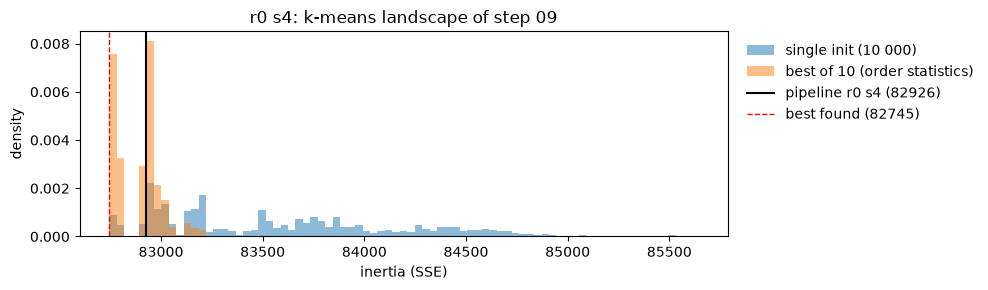

In [7]:
# cell 6: r0 s4: inertia of 10 000 single inits and of best-of-10 (order statistics), with the pipeline's inertia
import matplotlib.pyplot as plt
s_32, _ = ls.singles(RUN, n=10000)
J_32 = s_32["J"]
w_32 = ls.best_of_weights(J_32, 10)
bins_32 = np.linspace(J_32.min(), np.quantile(J_32, 0.995), 80)
fig, ax = plt.subplots(figsize=(10, 3))
ax.hist(J_32, bins=bins_32, density=True, alpha=0.5, label="single init (10 000)")
ax.hist(J_32, bins=bins_32, weights=w_32, density=True, alpha=0.5, label="best of 10 (order statistics)")
ax.axvline(p_21["inertia"], color="k", lw=1.5, label=f"pipeline r0 s4 ({p_21['inertia']:.0f})")
ax.axvline(J_32.min(), color="r", lw=1, ls="--", label=f"best found ({J_32.min():.0f})")
ax.set_xlabel("inertia (SSE)"); ax.set_ylabel("density"); ax.set_title("r0 s4: k-means landscape of step 09")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), frameon=False)
plt.tight_layout(); plt.show()

- **Kết quả**:
  - Phân bố inertia của lần khởi tạo đơn ở r0 s4 có nhiều đỉnh rời nhau: quanh 82750, quanh 82920–83000, quanh 83200, và một đuôi dài 83400–85600.
  - Best-of-10 dồn vào hai đỉnh: đỉnh sâu nhất (82745–82800) và đỉnh 82900–83000. Pipeline (82926) nằm ở đỉnh thứ hai; nghiệm tốt nhất tìm được là 82745, cách 0.22%.
  - r0 s4 thuộc nhóm 7/15 ảnh chụp mà pipeline không ở nghiệm tốt nhất (3.1).
- **Ý nghĩa**:
  - Đúng như dự đoán. Landscape là các thung lũng rời nhau chứ không phải một dốc liên tục, nên kết quả của bước 09 là chọn một trong vài họ nghiệm. Ở r0 s4, P10_best là 0.17 (ngưỡng 0.95) và 0.44 (ngưỡng 0.90).
  - 82757 ở `04-loader` (đổi thứ tự hàng) nằm trong đỉnh sâu nhất: một lần rút khác đã rơi vào thung lũng thấp hơn.

### 3.3 Dao động của chính thủ tục pipeline trên một pool cố định

Coi thủ tục của bước 09 (best-of-10) là một biến ngẫu nhiên trên mỗi pool, đo xem hai lần chạy độc lập khác nhau bao nhiêu:
- E[ARI] giữa hai lần chạy best-of-10: Monte Carlo, 4000 cặp rút theo trọng số `best_of_weights`. So với E[ARI] giữa hai lần khởi tạo đơn.
- P(cùng phân hoạch) = Σ W_p² và P(cùng nhóm nghiệm, ngưỡng 0.95) = Σ W_m², với W là xác suất best-of-10 rơi vào phân hoạch hoặc nhóm đó. Hai xác suất này tính chính xác từ trọng số.
- Độ bất ổn từng ảnh d_i = trung bình theo j của 2·c_ij·(1 − c_ij), với c_ij là xác suất (theo best-of-10) để ảnh i và j cùng cụm; đây là ma trận đồng xuất hiện (co-association; Fred & Jain 2005).

**Cách làm**: phép kiểm là đồng nhất thức trung bình d_i = 1 − E[Rand index] giữa hai lần chạy độc lập (Rand 1971). Vế phải tính lại từ chính 4000 cặp Monte Carlo; hai vế phải lệch nhau trong mức sai số Monte Carlo. Vector d_i của mỗi ảnh chụp được giữ lại (`D_33`) cho `09d-ownership`.

Dự đoán [SUY LUẬN]:
- E[ARI] giữa hai lần chạy pipeline khoảng 0.75–0.95; thấp hơn ở các ảnh chụp có P10_best nhỏ (r0, r2 s0, r2 s3);
- P(cùng phân hoạch) 0.02–0.3; P(cùng nhóm nghiệm) 0.1–0.5;
- trung bình d_i 0.02–0.08, phân bố lệch phải: đa số ảnh ổn định, một phần nhỏ ảnh đổi cụm giữa các họ nghiệm.

In [8]:
# cell 7: spread of the pipeline's own procedure (best-of-10) on a fixed pool: ARI between two independent runs,
#         chance of the same partition / mode, per-image instability d_i (kept in D_33 for 09d-ownership)
def rand_index_33(a, b, k=5):
    n = np.bincount(a.astype(np.int64) * k + b, minlength=k * k).reshape(k, k).astype(float)
    c2 = lambda v: (v * (v - 1) / 2).sum()
    t = len(a) * (len(a) - 1) / 2
    return (t + 2 * c2(n) - c2(n.sum(1)) - c2(n.sum(0))) / t

rng_33 = np.random.RandomState(33)
rows_33, D_33 = [], {}
for run in RUNS:
    s, _ = ls.singles(run, n=10000)
    L, J = s["L"], s["J"]
    w10 = ls.best_of_weights(J, 10)
    i, j = rng_33.choice(len(J), 4000, p=w10), rng_33.choice(len(J), 4000, p=w10)
    a10 = np.array([ls.ari(L[a], L[b], 5) for a, b in zip(i, j)])
    ri10 = np.array([rand_index_33(L[a], L[b]) for a, b in zip(i, j)])
    u, v = rng_33.randint(len(J), size=4000), rng_33.randint(len(J), size=4000)
    a1 = np.array([ls.ari(L[a], L[b], 5) for a, b in zip(u, v)])
    pid = {}
    inv = np.array([pid.setdefault(r.tobytes(), len(pid)) for r in L])
    Wp = np.bincount(inv, weights=w10)
    Wm = np.bincount(MD[(run, 0.95)]["mode"], weights=w10)
    d = ls.instability(L, w10)
    D_33[run] = d
    rows_33.append(dict(run=run[11:], E_ari_single=a1.mean(), E_ari_run=a10.mean(), ari_run_q05=np.quantile(a10, 0.05),
                        P_same_partition=(Wp ** 2).sum(), P_same_mode95=(Wm ** 2).sum(),
                        mean_d=d.mean(), one_minus_E_RI=1 - ri10.mean(), d_q50=np.median(d), d_q90=np.quantile(d, 0.9),
                        d_max=d.max(), share_d_gt_0_1=(d > 0.1).mean()))
df_33 = pd.DataFrame(rows_33)
print(df_33.to_string(index=False, float_format=lambda v: f"{v:.3g}"))

  run  E_ari_single  E_ari_run  ari_run_q05  P_same_partition  P_same_mode95  mean_d  one_minus_E_RI  d_q50  d_q90  d_max  share_d_gt_0_1
r0_s0         0.603      0.769         0.53            0.0119          0.213  0.0845          0.0842 0.0827  0.138  0.263            0.25
r0_s1         0.605      0.785        0.534            0.0245          0.201  0.0769          0.0776 0.0686 0.0944  0.266          0.0882
r0_s2         0.599      0.751        0.532           0.00775          0.136  0.0903          0.0908 0.0895  0.151  0.269           0.258
r0_s3         0.606      0.774        0.532           0.00505          0.163  0.0818          0.0831 0.0801 0.0995  0.278          0.0989
r0_s4         0.607      0.769        0.532           0.00701          0.106  0.0849          0.0844 0.0807   0.11  0.276           0.218
r1_s0         0.661      0.887        0.574           0.00608          0.516  0.0409          0.0415 0.0293 0.0694   0.31          0.0588
r1_s1         0.671      0.859    

- **Kết quả**:
  - E[ARI] giữa hai lần chạy pipeline (best-of-10) trên cùng một pool: r0 0.75–0.79, r1 0.86–0.90, r2 0.75–0.82. Phân vị 5% là 0.53–0.65. Giữa hai lần khởi tạo đơn: 0.60–0.68.
  - P(hai lần chạy pipeline cho cùng phân hoạch) chỉ 0.005–0.038. P(cùng nhóm nghiệm, ngưỡng 0.95) là 0.11–0.52; FT seed r1 cao nhất (0.33–0.52).
  - Trung bình d_i: 0.037–0.090. Phép kiểm đạt: trung bình d_i khớp 1 − E[Rand index] tính lại từ 4000 cặp, lệch tối đa 0.0015.
  - Phân bố d_i:
    - ở r0 và r2 bất ổn trải rộng: trung vị gần bằng trung bình (r0: 0.069–0.090), 9–49% số ảnh có d_i > 0.1;
    - ở r1 bất ổn dồn vào ít ảnh hơn: trung vị 0.026–0.032, trung bình 0.037–0.050;
    - d_i lớn nhất 0.26–0.31 (mức tối đa có thể là 0.5).
- **Ý nghĩa**:
  - Chỉ riêng may rủi khởi tạo, với pool và đặc trưng giữ nguyên, hai lần chạy bước 09 đã khác nhau tới mức ARI trung bình 0.77 ở r0. ARI 0.73 ở `04-loader` là một lần rút bình thường, không phải trường hợp hiếm.
  - Các lần chạy gần như không bao giờ ra trùng hẳn một phân hoạch, nhưng hay rơi vào cùng một họ nghiệm. Độ ổn định khác nhau theo FT seed (r1 ổn định nhất), tức phụ thuộc biểu diễn chứ không chỉ k-means.
  - Dự đoán đúng ở khoảng E[ARI]. Sai ở P(cùng phân hoạch), thấp hơn dự đoán 0.02–0.3. Sai ở hình dạng phân bố d_i với r0: bất ổn trải rộng chứ không dồn vào một phần nhỏ ảnh.
  - [SUY LUẬN] Phần dao động giữa các seed của mọi đại lượng tầng 2 có một nguồn lớn ngay ở bước 09. Đây là nhiễu mà E09.07 lấy trung bình qua 11 lần rút (QD26). Ảnh nào hay đổi cụm thuộc lớp nào thì để `09d-ownership` trả lời, dùng `D_33`.

### 3.4 Đổi thứ tự hàng có phải là rút khởi tạo mới không (r0 s4)

QD26 lập luận rằng giữ trạng thái RNG cố định mà đổi thứ tự hàng thì phân phối nghiệm giống hệt rút khởi tạo mới, vì k-means++ chọn tâm theo chỉ số hàng còn Lloyd không phụ thuộc thứ tự (2.1). Lập luận đã được thử trên dữ liệu đồ chơi; ở đây kiểm trên dữ liệu thật.

**Cách làm**:
- Mẫu cần kiểm: 1.000 lần chạy `n_init` 10 ở r0 s4, cùng `rng_in`, hàng hoán vị ngẫu nhiên (cache `permuted`).
- Mẫu tham chiếu: 1.000 lần best-of-10 rút bootstrap từ 10.000 lần khởi tạo đơn của luồng riêng.
- So inertia bằng thống kê KS D (Kolmogorov–Smirnov hai mẫu). So nhóm nghiệm (ngưỡng 0.95, gán bằng `assign`) bằng khoảng cách biến phân toàn phần (total variation, TV).
- Mức nền: 200 cặp mẫu bootstrap độc lập cùng cỡ cho phân vị 95% của D và của TV. Inertia rời rạc nên p-value của KS chỉ để tham khảo; mức nền bootstrap mới là chuẩn so.

Dự đoán:
- D và TV của mẫu hoán vị nằm dưới phân vị 95% của mức nền;
- tỷ lệ rơi vào nhóm sâu nhất ≈ P10_best = 0.17;
- số lần trùng hẳn nghiệm pipeline ≈ 1000 × (xác suất best-of-10 cho đúng phân hoạch đó).

In [9]:
# cell 8: row order = a new init draw? 1 000 pipeline runs (n_init 10) from rng_in of r0 s4 with permuted rows,
#         against best-of-10 drawn (bootstrap) from the 10 000 single inits of an independent stream
from scipy.stats import ks_2samp
P_34, _ = ls.permuted(RUN, m=1000)
s_34, _ = ls.singles(RUN, n=10000)
L_34, J_34 = s_34["L"], s_34["J"]
w_34 = ls.best_of_weights(J_34, 10)
md_34 = MD[(RUN, 0.95)]
rng_34 = np.random.RandomState(34)

def boot_34(m):                                    # m best-of-10 runs from the singles: index of the kept single
    idx = rng_34.randint(len(J_34), size=(m, 10))
    return idx[np.arange(m), J_34[idx].argmin(1)]

def tv_34(x, y):                                   # total variation between two samples of mode ids (-1 = no mode)
    K = max(x.max(), y.max()) + 2
    return 0.5 * np.abs(np.bincount(x + 1, minlength=K) / len(x) - np.bincount(y + 1, minlength=K) / len(y)).sum()

mode_perm = np.array([ls.assign(l, L_34, md_34, 0.95)[0] for l in P_34["L"]])
b_34 = boot_34(1000)
null_D, null_TV = [], []
for _ in range(200):
    x, y = boot_34(1000), boot_34(1000)
    null_D.append(ks_2samp(J_34[x], J_34[y]).statistic)
    null_TV.append(tv_34(md_34["mode"][x], md_34["mode"][y]))
ks_34 = ks_2samp(P_34["J"], J_34[b_34])
print(f"inertia KS D perm vs boot {ks_34.statistic:.3f} (p {ks_34.pvalue:.2f}) | null D q95 {np.quantile(null_D, 0.95):.3f}")
print(f"mode TV perm vs boot {tv_34(mode_perm, md_34['mode'][b_34]):.3f} | null TV q95 {np.quantile(null_TV, 0.95):.3f}")
print(f"share in the deepest mode: perm {(mode_perm == 0).mean():.3f} | boot {(md_34['mode'][b_34] == 0).mean():.3f}"
      f" | exact P10_best {w_34[md_34['mode'] == 0].sum():.3f} | perm runs outside every mode {(mode_perm == -1).mean():.3f}")
pipe_34 = ls.canon(ls.pool(RUN)["ids"])
print(f"perm runs equal to the pipeline partition: {int((P_34['L'] == pipe_34).all(1).sum())} / 1000"
      f" | expected from best-of-10: {1000 * w_34[(L_34 == pipe_34).all(1)].sum():.1f}")

inertia KS D perm vs boot 0.089 (p 0.00) | null D q95 0.058
mode TV perm vs boot 0.103 | null TV q95 0.098
share in the deepest mode: perm 0.155 | boot 0.181 | exact P10_best 0.170 | perm runs outside every mode 0.000
perm runs equal to the pipeline partition: 8 / 1000 | expected from best-of-10: 8.1


- **Kết quả**:
  - Inertia: KS D giữa mẫu hoán vị và mẫu tham chiếu là 0.089 (p < 0.01), vượt phân vị 95% của mức nền (0.058).
  - Nhóm nghiệm (ngưỡng 0.95): TV 0.103, sát phân vị 95% của mức nền (0.098).
  - Tỷ lệ rơi vào nhóm sâu nhất: mẫu hoán vị 0.155, mẫu tham chiếu 0.181; giá trị tính chính xác từ trọng số (P10_best) là 0.170. Không lần chạy hoán vị nào nằm ngoài mọi nhóm nghiệm.
  - Trùng hẳn nghiệm của pipeline: 8/1000 lần, kỳ vọng từ best-of-10 là 8.1.
- **Ý nghĩa**:
  - Hai phép đo không phụ thuộc giá trị inertia (tỷ lệ nhóm sâu nhất, số lần trùng hẳn nghiệm pipeline) khớp với lập luận. Phép KS trên inertia thì trượt, TV ở nhóm nghiệm nằm sát ngưỡng.
  - Chưa kết luận được trước khi loại hai nguồn sai số của chính phép đo, kiểm ở 3.4b:
    - [SUY LUẬN] Hoán vị hàng đổi thứ tự cộng float32 trong Lloyd và trong inertia, nên cùng một phân hoạch có thể ra inertia lệch ở vài chữ số cuối. Mẫu tham chiếu có những giá trị inertia lặp lại nhiều lần (các phân hoạch xuất hiện hàng chục lần, 3.1). Ở những điểm lặp đó, KS D rất nhạy với độ lệch nhỏ như vậy.
    - Mẫu hoán vị được gán nhóm bằng `assign`, còn mẫu tham chiếu dùng nhóm do `modes` gán. Hai cách gán có thể khác nhau với phân hoạch khớp một nghiệm đầu nhóm sinh sau (inertia cao hơn).

### 3.4b Phép so ở 3.4 có trượt vì chính cách đo không

Hai phép kiểm trên cùng dữ liệu ở 3.4, không chạy thêm k-means:
1. **Độ lệch số thực**: với mỗi lần chạy hoán vị có phân hoạch xuất hiện y hệt trong 10.000 lần khởi tạo đơn, so hai giá trị inertia của cùng phân hoạch đó. Sau đó tính lại KS trên inertia đã làm tròn tới 1e-6 và 1e-5 tương đối (khoảng 0.08 và 0.8 đơn vị SSE). Mức nền làm tròn y như vậy.
2. **Cùng cách gán nhóm**: gán nhóm cho cả 10.000 lần khởi tạo đơn bằng `assign`, giống mẫu hoán vị, rồi tính lại TV và mức nền. Kèm theo: số lần khởi tạo đơn mà `assign` và `modes` gán khác nhau.

Dự đoán [SUY LUẬN]:
- cùng phân hoạch mà inertia lệch khoảng 1e-7 tương đối, hiếm khi trùng hẳn;
- sau khi làm tròn, D xuống dưới phân vị 95% của mức nền;
- TV với cùng cách gán nằm dưới mức nền;
- `assign` và `modes` gán khác nhau ở dưới 1% số lần khởi tạo.

Nếu sau hai phép kiểm này vẫn trượt, lập luận "đổi thứ tự hàng = rút khởi tạo mới" không đứng được trên dữ liệu thật và Q09.12 phải ghi lại như vậy.

In [10]:
# cell 9: does 3.4 fail because of the measurement? (1) same partition, other float32 summation order -> inertia
#         differs in the last bits: KS on rounded inertia; (2) modes assigned the same way (assign) on both sides
first_35 = {}
for i, r in enumerate(L_34):
    first_35.setdefault(r.tobytes(), i)
hit_35 = np.array([first_35.get(r.tobytes(), -1) for r in P_34["L"]])
m_35 = hit_35 >= 0
rel_35 = np.abs(P_34["J"][m_35] - J_34[hit_35[m_35]]) / J_34[hit_35[m_35]]
print(f"perm runs whose exact partition occurs in the singles: {m_35.sum()} / 1000 | inertia rel. diff for the same "
      f"partition: median {np.median(rel_35):.1e}, max {rel_35.max():.1e}, exactly equal {(rel_35 == 0).mean():.2f}")
for dec in (6, 5):
    rd = lambda x: np.round(x / J_34.min(), dec)
    nD = [ks_2samp(rd(J_34[x]), rd(J_34[y])).statistic for x, y in ((boot_34(1000), boot_34(1000)) for _ in range(200))]
    print(f"KS D, inertia rounded to 1e-{dec} relative: perm vs boot {ks_2samp(rd(P_34['J']), rd(J_34[b_34])).statistic:.3f}"
          f" | null q95 {np.quantile(nD, 0.95):.3f}")
t0_35 = time.time()
mode_a_35 = np.array([ls.assign(l, L_34, md_34, 0.95)[0] for l in L_34])        # same assignment rule as mode_perm
print(f"assign vs modes on the 10 000 singles: {(mode_a_35 != md_34['mode']).sum()} differ ({time.time() - t0_35:.0f} s)")
nTV = [tv_34(mode_a_35[x], mode_a_35[y]) for x, y in ((boot_34(1000), boot_34(1000)) for _ in range(200))]
print(f"mode TV (assign on both sides): perm vs boot {tv_34(mode_perm, mode_a_35[b_34]):.3f} | null q95 {np.quantile(nTV, 0.95):.3f}"
      f" | deepest-mode share perm {(mode_perm == 0).mean():.3f} vs best-of-10 {w_34[mode_a_35 == 0].sum():.3f}")

perm runs whose exact partition occurs in the singles: 812 / 1000 | inertia rel. diff for the same partition: median 3.8e-07, max 1.6e-06, exactly equal 0.06
KS D, inertia rounded to 1e-6 relative: perm vs boot 0.089 | null q95 0.059
KS D, inertia rounded to 1e-5 relative: perm vs boot 0.087 | null q95 0.056
assign vs modes on the 10 000 singles: 0 differ (30 s)
mode TV (assign on both sides): perm vs boot 0.103 | null q95 0.099 | deepest-mode share perm 0.155 vs best-of-10 0.170


- **Kết quả**:
  - 812/1000 lần chạy hoán vị có phân hoạch xuất hiện y hệt trong 10.000 lần khởi tạo đơn. Với cùng một phân hoạch, inertia lệch tương đối trung vị 3.8e-7, tối đa 1.6e-6; chỉ 6% trùng hẳn.
  - Làm tròn inertia không đổi kết quả: KS D 0.089 (làm tròn 1e-6) và 0.087 (làm tròn 1e-5), vẫn vượt phân vị 95% của mức nền (0.059 và 0.056).
  - `assign` và `modes` gán nhóm giống hệt nhau trên cả 10.000 lần khởi tạo đơn (0 khác biệt). Với cùng cách gán ở hai phía, TV vẫn là 0.103, sát mức nền 0.099.
  - Tỷ lệ rơi vào nhóm sâu nhất: mẫu hoán vị 0.155, best-of-10 0.170.
- **Ý nghĩa**:
  - Hai nguồn sai số của phép đo đã bị loại, nên phép kiểm này **bác** khẳng định "cùng trạng thái RNG, đổi thứ tự hàng thì cho cùng phân phối với rút khởi tạo mới" (QD26, ghi chú ở Q09.12). Khẳng định đó sai về toán.
  - Vì sao sai: k-means++ chọn các tâm sau bằng `searchsorted(tổng tích luỹ D², u·tổng)`. Chỉ khi u là số ngẫu nhiên đều thì xác suất chọn mỗi điểm mới tỷ lệ với D². Khi giữ trạng thái RNG cố định thì u cố định, và hoán vị chỉ làm xáo vị trí các điểm quanh một mức tích luỹ cố định.
  - Ví dụ 7 điểm, trọng số D² là 10, 5, 1, 1, 1, 1, 1 (200.000 lần hoán vị):
    - u = 0.03 hoặc 0.97: mỗi điểm được chọn với tần suất khoảng 0.14, gần như đều;
    - u = 0.5: điểm nặng nhất được chọn 0.86 lần, trong khi D² chỉ cho 0.50.
  - Phép thử trên dữ liệu đồ chơi trước đó không đủ nhạy để thấy chỗ này.
  - Phần còn đúng:
    - Đổi thứ tự hàng vẫn tác động qua đúng cơ chế chọn tâm, nên tạo ra dao động cùng loại với dao động khởi tạo và cùng cỡ ở cấp nhóm nghiệm: nhóm sâu nhất 0.155 so với 0.170; trùng nghiệm pipeline 8 so với 8.1 lần.
    - Khi cả thứ tự hàng lẫn trạng thái RNG đều đổi (u ngẫu nhiên), việc chọn tâm đúng là lấy mẫu theo D². Đó là trường hợp giữa các seed của pipeline (bước 04 xáo hàng, RNG đổi theo seed), nên dao động giữa các seed vẫn là dao động của rút khởi tạo mới. 3.5 dựa vào điều này.
  - Không ảnh hưởng E09.07: các lần rút ở đó dùng luồng RNG mới hoặc `rng_in`, không dùng hoán vị hàng.
  - Cần sửa ghi chép (làm trong đợt ghi chép cuối notebook): thêm dòng sửa có ngày vào QD26 và Q09.12; thêm ghi chú vào E09.07, không sửa phần tiền đăng ký, vì dòng "đã thấy" ở đó ghi đúng kết quả thử trên dữ liệu đồ chơi.

### 3.5 Các seed trong cùng một FT seed: may rủi khởi tạo hay 50 ảnh reserve

Năm seed của cùng một FT seed dùng cùng file đặc trưng. Chúng chỉ khác nhau ở thứ tự hàng và trạng thái RNG (cùng nhau tương đương rút khởi tạo mới, 3.4b), và ở 50 ảnh reserve bốc theo seed.

Câu hỏi: năm nghiệm của pipeline có giống năm lần rút từ gần như cùng một landscape không?

**Cách làm** (không nhãn):
- Ảnh chung của 5 pool: khớp theo byte của dòng đặc trưng.
- Với mỗi cặp seed (a, b), tính trên ảnh chung:
  - ARI giữa hai nghiệm pipeline;
  - E[ARI] giữa hai lần best-of-10 trong pool a (1000 cặp);
  - ARI lớn nhất giữa nghiệm pipeline của seed b và 10.000 lần khởi tạo đơn của seed a, cho biết nghiệm của b có mặt trong landscape của a không;
  - khối lượng best-of-10 của a nằm trong ARI ≥ 0.95 quanh nghiệm của b.

Dự đoán [SUY LUẬN]:
- khoảng 698 ảnh chung (698 ảnh S1 cộng vài ảnh reserve trùng ở cả 5 seed);
- ARI giữa hai seed ≈ E[ARI] trong một pool (r0 ~0.77, r1 ~0.88);
- ARI lớn nhất ≥ 0.98 ở hầu hết các cặp, và khối lượng best-of-10 quanh nghiệm của b cùng cỡ xác suất các nhóm nghiệm (0.1–0.5).

Nếu đúng, phần khác nhau giữa các seed ở bước 09 gần như toàn bộ là may rủi khởi tạo; 50 ảnh reserve gần như không đổi landscape.

In [11]:
# cell 10: the 5 seeds of one FT seed on their common images (matched by feature bytes): pairwise ARI of the pipeline
#          partitions vs the within-pool expectation; each pipeline partition located in the other seeds' landscapes
rng_35 = np.random.RandomState(35)
rows_35 = []
for r in range(3):
    runs = [f"gc10_v2_ft_r{r}_s{s}" for s in range(5)]
    P = {run: ls.pool(run) for run in runs}
    rowkey = {run: {x.tobytes(): i for i, x in enumerate(P[run]["x"])} for run in runs}
    common = sorted(set.intersection(*(set(k) for k in rowkey.values())))
    idx = {run: np.array([rowkey[run][k] for k in common]) for run in runs}
    S = {run: ls.singles(run, n=10000)[0] for run in runs}
    W = {run: ls.best_of_weights(S[run]["J"], 10) for run in runs}
    pipe = {run: ls.canon(P[run]["ids"])[idx[run]] for run in runs}
    for a in runs:
        La = S[a]["L"][:, idx[a]]
        i, j = rng_35.choice(10000, 1000, p=W[a]), rng_35.choice(10000, 1000, p=W[a])
        e_within = float(np.mean([ls.ari(La[x], La[y], 5) for x, y in zip(i, j)]))
        for b in runs:
            if b != a:
                ar = ls.ari_many(pipe[b], La, 5)            # pipeline partition of b vs every single init of a
                rows_35.append(dict(r=r, a=a[-2:], b=b[-2:], n_common=len(common), ari_pipe=ls.ari(pipe[a], pipe[b], 5),
                                    E_within_a=e_within, max_ari_b_in_a=float(ar.max()), P10_near_b_in_a=float(W[a][ar >= 0.95].sum())))
df_35 = pd.DataFrame(rows_35)
for r in range(3):
    d = df_35[df_35.r == r]
    print(f"\nFT seed r{r}: {d.n_common.iloc[0]} common images | E[ARI] of two runs within one pool (per a):",
          d.groupby("a").E_within_a.first().round(3).to_dict())
    for col in ("ari_pipe", "max_ari_b_in_a", "P10_near_b_in_a"):
        print(f"{col} (rows a, columns b):")
        print(d.pivot(index="a", columns="b", values=col).round(3).to_string())


FT seed r0: 700 common images | E[ARI] of two runs within one pool (per a): {'s0': 0.778, 's1': 0.804, 's2': 0.754, 's3': 0.78, 's4': 0.78}
ari_pipe (rows a, columns b):
b      s0     s1     s2     s3     s4
a                                    
s0    NaN  0.995  0.668  0.743  0.749
s1  0.995    NaN  0.665  0.741  0.747
s2  0.668  0.665    NaN  0.427  0.427
s3  0.743  0.741  0.427    NaN  0.978
s4  0.749  0.747  0.427  0.978    NaN
max_ari_b_in_a (rows a, columns b):
b      s0     s1     s2     s3     s4
a                                    
s0    NaN  0.999  1.000  0.996  1.000
s1  0.995    NaN  0.995  0.971  0.980
s2  0.998  0.994    NaN  0.987  0.998
s3  0.995  0.994  0.992    NaN  1.000
s4  1.000  0.995  0.988  1.000    NaN
P10_near_b_in_a (rows a, columns b):
b      s0     s1     s2     s3     s4
a                                    
s0    NaN  0.326  0.005  0.079  0.078
s1  0.302    NaN  0.005  0.227  0.233
s2  0.289  0.284    NaN  0.114  0.113
s3  0.381  0.368  0.007    NaN  0.

- **Kết quả**: mỗi FT seed có 700 ảnh chung giữa 5 pool (698 ảnh S1 và 2 ảnh reserve có mặt ở cả 5 seed).
  - **Nghiệm của mỗi seed có trong landscape của seed khác**: ARI lớn nhất giữa nghiệm pipeline của seed b và 10.000 lần khởi tạo đơn của seed a là 0.971–1.000 ở cả 60 cặp, và ≥ 0.98 ở 58/60 cặp.
  - **ARI giữa nghiệm pipeline của hai seed**, so với E[ARI] giữa hai lần chạy trong cùng một pool:

    | FT seed | ARI giữa hai seed | trung bình 10 cặp | E[ARI] trong một pool |
    |---|---|---|---|
    | r0 | 0.43–0.995 | 0.71 | 0.75–0.80 (trung bình 0.78) |
    | r1 | 0.68–0.97 | 0.82 | 0.88–0.91 (trung bình 0.90) |
    | r2 | 0.58–1.00 | 0.72 | 0.76–0.83 (trung bình 0.79) |

  - Một số cặp trùng gần như hẳn: r0 s0–s1 0.995, r0 s3–s4 0.978, r2 s2–s4 1.000.
  - **Khối lượng best-of-10 của seed a quanh nghiệm của seed b** (ARI ≥ 0.95) trải từ 0.001 đến 0.71. Có nghiệm hiếm ở mọi landscape: nghiệm của r0 s2 chỉ chiếm 0.001–0.007, của r1 s4 chỉ 0.002–0.017. Nghiệm của r0 s0, s1 và r1 s0–s2 thì phổ biến (0.23–0.71).
- **Ý nghĩa**:
  - Không seed nào có nghiệm "riêng" do 50 ảnh reserve tạo ra: nghiệm của mỗi seed đều là một cực tiểu có sẵn trong landscape của các seed kia. Khác nhau giữa các seed ở bước 09 chủ yếu là chuyện rơi vào cực tiểu nào.
  - Hai nghiệm r0 s2 và r1 s4 là những lần rút hiếm (r0 s2 cũng cách xa nghiệm tốt nhất trong chính pool của nó, 3.1). Chúng kéo trung bình ARI giữa các seed xuống.
  - ARI giữa hai seed thấp hơn E[ARI] trong một pool khoảng 0.07 ở cả 3 FT seed. Với 10 cặp phụ thuộc nhau mỗi FT seed, phép so này chưa đủ để tách may rủi khởi tạo khỏi một ảnh hưởng nhỏ của ảnh reserve. 3.5b so trực tiếp kỳ vọng giữa hai landscape.

### 3.5b Hai landscape có cùng phân phối nghiệm không

Thay vì 10 cặp nghiệm pipeline (mỗi seed chỉ là một lần rút), so hai kỳ vọng tính trên ảnh chung:
- E_cross(a, b): E[ARI] giữa một lần best-of-10 rút từ landscape a và một lần rút từ landscape b;
- E_within(a): E[ARI] giữa hai lần best-of-10 cùng rút từ landscape a (đã tính ở 3.5).

Mỗi kỳ vọng tính bằng Monte Carlo 1000 cặp. Nếu 50 ảnh reserve không đổi phân phối nghiệm thì E_cross ≈ E_within. Sai số Monte Carlo khoảng 0.006, ước theo độ lệch chuẩn của ARI (khoảng 0.2) chia √1000.

Dự đoán [SUY LUẬN]: E_cross thấp hơn E_within không quá 0.02, tức ảnh hưởng của ảnh reserve không đáng kể. Khi đó khoảng chênh 0.07 ở 3.5 là do chính các lần rút của pipeline (có seed rơi vào nghiệm hiếm), không do landscape khác nhau.

In [12]:
# cell 11: do two seeds of one FT seed have the same distribution of solutions? E[ARI] of best-of-10 draws across two
#          landscapes vs within one landscape, on the common images (Monte Carlo, 1000 pairs each)
rng_35b = np.random.RandomState(351)
rows_35b = []
for r in range(3):
    runs = [f"gc10_v2_ft_r{r}_s{s}" for s in range(5)]
    P = {run: ls.pool(run) for run in runs}
    rowkey = {run: {x.tobytes(): i for i, x in enumerate(P[run]["x"])} for run in runs}
    common = sorted(set.intersection(*(set(k) for k in rowkey.values())))
    Lc = {run: ls.singles(run, n=10000)[0]["L"][:, [rowkey[run][k] for k in common]] for run in runs}
    W = {run: ls.best_of_weights(ls.singles(run, n=10000)[0]["J"], 10) for run in runs}
    for a in runs:
        for b in runs:
            i, j = rng_35b.choice(10000, 1000, p=W[a]), rng_35b.choice(10000, 1000, p=W[b])
            rows_35b.append(dict(r=r, a=a[-2:], b=b[-2:], E=float(np.mean([ls.ari(Lc[a][x], Lc[b][y], 5) for x, y in zip(i, j)]))))
df_35b = pd.DataFrame(rows_35b)
for r in range(3):
    d = df_35b[df_35b.r == r]
    within, cross = d[d.a == d.b].E, d[d.a != d.b].E
    print(f"\nFT seed r{r}: E_within mean {within.mean():.3f} (range {within.min():.3f}-{within.max():.3f}) | "
          f"E_cross mean {cross.mean():.3f} (range {cross.min():.3f}-{cross.max():.3f}) | difference {cross.mean() - within.mean():+.3f}")
    print(d.pivot(index="a", columns="b", values="E").round(3).to_string())


FT seed r0: E_within mean 0.775 (range 0.760-0.795) | E_cross mean 0.768 (range 0.755-0.782) | difference -0.007
b      s0     s1     s2     s3     s4
a                                    
s0  0.769  0.772  0.759  0.774  0.766
s1  0.768  0.795  0.772  0.782  0.770
s2  0.767  0.767  0.760  0.755  0.759
s3  0.772  0.781  0.765  0.776  0.767
s4  0.762  0.773  0.760  0.766  0.775

FT seed r1: E_within mean 0.896 (range 0.878-0.909) | E_cross mean 0.876 (range 0.851-0.906) | difference -0.020
b      s0     s1     s2     s3     s4
a                                    
s0  0.903  0.851  0.892  0.865  0.906
s1  0.857  0.888  0.859  0.882  0.865
s2  0.898  0.858  0.909  0.864  0.900
s3  0.865  0.885  0.870  0.878  0.868
s4  0.901  0.856  0.902  0.869  0.902

FT seed r2: E_within mean 0.793 (range 0.755-0.832) | E_cross mean 0.781 (range 0.756-0.818) | difference -0.012
b      s0     s1     s2     s3     s4
a                                    
s0  0.755  0.771  0.756  0.762  0.763
s1  0.768  0

- **Kết quả**:
  - E_cross thấp hơn E_within: r0 −0.007, r1 −0.020, r2 −0.012. Sai số Monte Carlo khoảng 0.006 cho mỗi ô.
  - r1 có cấu trúc rõ: s1 và s3 giống nhau (E_cross 0.88–0.89) nhưng khác s0, s2, s4 (0.85–0.87); ba seed s0, s2, s4 giống nhau (0.89–0.91).
- **Ý nghĩa**:
  - Đúng như dự đoán. Phân phối nghiệm của năm seed gần như trùng nhau; 50 ảnh reserve chỉ dịch nhẹ tần suất các nhóm nghiệm, thấy rõ nhất ở r1 (−0.02 ARI).
  - Khoảng chênh 0.07 ở 3.5 phần lớn đến từ chính các lần rút của pipeline (r0 s2, r1 s4 rơi vào nghiệm hiếm), không đến từ landscape khác nhau.
  - Kết luận cho Q09.12: trong một FT seed, khác biệt giữa các seed ở bước 09 gần như toàn bộ là may rủi khởi tạo trên một landscape gần như cố định. [SUY LUẬN] Mọi so sánh theo seed ở tầng 2 trong cùng FT seed chủ yếu đo may rủi này; đó là lý do E09.07 lấy trung bình 11 lần rút trong mỗi ảnh chụp.

## 4. Cụm, camera và cuộn (không nhãn)

### 4.1 Camera và cuộn của từng ảnh pool

Gắn mỗi hàng `pool_x` của 15 ảnh chụp với ảnh của nó theo byte trong file đặc trưng train (như `05a-camera`), rồi lấy camera và cuộn từ tên file `img_<cam>_<coil>_<frame>.jpg` (`data_io.images`). Chỉ đọc các cột `part`, `row`, `cam`, `coil`; không đọc lớp hay vai trò ảnh.

Dự đoán: 748/748 hàng gắn được ảnh ở mọi ảnh chụp; 8 camera; khoảng 99 cuộn của 698 ảnh S1, cộng thêm các cuộn của 50 ảnh reserve.

In [13]:
# cell 12: camera and coil of every pool row of the 15 snapshots (rows matched to images by their bytes in the train
#          feature file; file-name fields only: no class, no role)
import data_io
img_41 = data_io.images("gc10")[["part", "row", "cam", "coil"]]
tr_41 = img_41[img_41.part == "train"].set_index("row")
CC, pos_41 = {}, {}
for run in RUNS:
    a = replay.snapshots(run)["04"]["meta"]["args"]
    F = Path(a["data_dir"]) / a["pretrained_model_name"]
    if F not in pos_41:
        X = np.load(F / f"features-{F.name}.npy")
        pos_41[F] = {r.tobytes(): i for i, r in enumerate(X)}
    rows = [pos_41[F][x.tobytes()] for x in ls.pool(run)["x"]]
    CC[run] = tr_41.loc[rows, ["cam", "coil"]].reset_index(drop=True)
print(pd.DataFrame([dict(run=r[11:], rows=len(c), cams=c.cam.nunique(), coils=c.coil.nunique()) for r, c in CC.items()]).to_string(index=False))
print("r0 s4 images per camera:", CC[RUN].cam.value_counts().sort_index().to_dict())

  run  rows  cams  coils
r0_s0   748     8    131
r0_s1   748     8    129
r0_s2   748     8    129
r0_s3   748     8    129
r0_s4   748     8    129
r1_s0   748     8    131
r1_s1   748     8    129
r1_s2   748     8    129
r1_s3   748     8    129
r1_s4   748     8    129
r2_s0   748     8    131
r2_s1   748     8    129
r2_s2   748     8    129
r2_s3   748     8    129
r2_s4   748     8    129
r0 s4 images per camera: {'01': 141, '02': 68, '03': 105, '04': 32, '05': 65, '06': 114, '07': 144, '08': 79}


- **Kết quả**: 748/748 hàng gắn được ảnh ở cả 15 ảnh chụp; đủ 8 camera; 129–131 cuộn. r0 s4 theo camera (01–08): 141, 68, 105, 32, 65, 114, 144, 79.
- **Ý nghĩa**: đúng như dự đoán. Số cuộn (129–131) gồm khoảng 99 cuộn của 698 ảnh S1 và các cuộn của 50 ảnh reserve.

### 4.2 Hình học của các cụm

Trên nghiệm của pipeline ở 15 ảnh chụp:
- cỡ cụm: hệ số biến thiên (CV), tỷ lệ cụm lớn nhất/nhỏ nhất (`cluster_max_min`, lưu cho Q09.03 ở 14);
- R² của phân hoạch = 1 − inertia / tổng bình phương;
- η² của chuẩn ‖x‖ theo cụm và theo camera, để xem camera có tác động qua độ lớn đặc trưng không;
- tổng bình phương giữa cụm nằm ở 3 và 10 thành phần chính (PC) đầu của pool bao nhiêu phần; η² của PC1–3 theo cụm.

**Cách làm**: η²(v | g) = Σ_g n_g (v̄_g − v̄)² / Σ (v − v̄)² (tỷ số tương quan, correlation ratio). Tổng bình phương giữa cụm chiếu lên PC c là Σ_k n_k (c_kᵀ u_c)², với c_k là tâm cụm k (đặc trưng đã trừ trung bình) và u_c là hướng của PC c.

Dự đoán [SUY LUẬN]:
- CV 0.24–0.57, trùng khoá `k5_size_cv` của E09.05;
- R² khoảng 0.3–0.4: ở r0 s4, tổng bình phương ≈ 748 × 768 × 0.218 ≈ 125.000, nên R² ≈ 1 − 82926/125060 ≈ 0.34;
- phần lớn (hơn 60%) tổng bình phương giữa cụm nằm ở 3 PC đầu;
- η² của ‖x‖ theo camera 0.1–0.4 (camera mạnh trong đặc trưng thô, `05a`).

In [14]:
# cell 13: geometry of the pipeline's clusters, label-free: sizes (CV, max/min), R^2 of the partition, eta^2 of the
#          feature norm by cluster and by camera, share of the between-cluster sum of squares in the top PCs of the pool
def eta2_42(v, g):
    g, m = np.asarray(g), v.mean()
    return sum((g == u).sum() * (v[g == u].mean() - m) ** 2 for u in np.unique(g)) / ((v - m) ** 2).sum()

rows_42 = []
for run in RUNS:
    p = ls.pool(run)
    x, ids = p["x"].astype(np.float64), p["ids"]
    xc = x - x.mean(0)
    _, S, Vt = np.linalg.svd(xc, full_matrices=False)
    n_k = np.bincount(ids)
    cent = np.stack([xc[ids == k].mean(0) for k in range(len(n_k))])
    B = (n_k[:, None] * cent ** 2).sum()                                     # between-cluster sum of squares
    Bpc = (n_k[:, None] * (cent @ Vt[:10].T) ** 2).sum(0)                    # ... along PC 1..10
    Z = xc @ Vt[:3].T
    nrm = np.linalg.norm(x, axis=1)
    rows_42.append(dict(run=run[11:], sizes=sorted(n_k.tolist(), reverse=True), size_cv=n_k.std(ddof=1) / n_k.mean(),
                        max_min=n_k.max() / n_k.min(), R2=B / (xc ** 2).sum(), eta2_norm_cluster=eta2_42(nrm, ids),
                        eta2_norm_camera=eta2_42(nrm, CC[run].cam.values), B_top3_pc=Bpc[:3].sum() / B,
                        B_top10_pc=Bpc.sum() / B, var_top3_pc=(S[:3] ** 2).sum() / (S ** 2).sum(),
                        eta2_pc1=eta2_42(Z[:, 0], ids), eta2_pc2=eta2_42(Z[:, 1], ids), eta2_pc3=eta2_42(Z[:, 2], ids)))
print(pd.DataFrame(rows_42).to_string(index=False, float_format=lambda v: f"{v:.3g}"))

  run                     sizes  size_cv  max_min    R2  eta2_norm_cluster  eta2_norm_camera  B_top3_pc  B_top10_pc  var_top3_pc  eta2_pc1  eta2_pc2  eta2_pc3
r0_s0    [257, 228, 90, 89, 84]    0.571     3.06 0.339              0.283            0.0212      0.884       0.981        0.391     0.894     0.746     0.259
r0_s1    [252, 227, 92, 89, 88]    0.552     2.86 0.338              0.299            0.0228      0.885       0.981        0.389     0.894     0.742     0.276
r0_s2   [255, 174, 140, 93, 86]    0.461     2.97 0.335               0.36            0.0242      0.867       0.985         0.39     0.875     0.726     0.222
r0_s3  [277, 156, 120, 105, 90]    0.503     3.08 0.339               0.27            0.0262      0.874       0.982        0.391     0.877     0.743     0.275
r0_s4  [272, 157, 121, 103, 95]    0.484     2.86 0.337              0.257            0.0192      0.875       0.982         0.39     0.877      0.73     0.298
r1_s0  [291, 134, 127, 105, 91]    0.541      

- **Kết quả**:
  - CV cỡ cụm 0.24–0.57, trùng khoá `k5_size_cv` của E09.05; cụm lớn nhất/nhỏ nhất 1.76–3.56.
  - R² của phân hoạch: r0 0.335–0.339, r1 0.303–0.307, r2 0.312–0.314.
  - 82–89% tổng bình phương giữa cụm nằm ở 3 PC đầu của pool, 98–99% ở 10 PC đầu. Riêng 3 PC đầu chỉ giữ 34–39% tổng phương sai.
  - η² theo cụm: PC1 0.85–0.90, PC2 0.73–0.78, PC3 0.15–0.54.
  - η² của ‖x‖ theo cụm: r0 0.26–0.36, r1 0.26–0.32, r2 0.04–0.09. Theo camera: r0 0.02, r1 0.21–0.22, r2 0.14–0.15.
- **Ý nghĩa**:
  - Đúng ở cỡ cụm, R² và PC. k-means ở 768 chiều thực chất chia pool theo 2–3 hướng có phương sai lớn nhất.
  - Sai ở η² của ‖x‖ theo camera (dự đoán 0.1–0.4; r0 chỉ 0.02). Quan hệ giữa ‖x‖, cụm và camera đổi theo FT seed: ở r0, ‖x‖ khác nhau giữa các cụm nhưng không khác giữa các camera; ở r2 thì ngược lại. Độ lớn đặc trưng không phải cơ chế chung để camera đi vào cụm.
  - [SUY LUẬN] Vì phân cụm dồn vào vài PC đầu, câu hỏi những PC đó mang lớp hay mang camera, cuộn (05a đã đo ở PCA-64 của S0) là câu then chốt cho `09d-ownership`.

### 4.3 Cụm × camera và cụm × cuộn (phần không nhãn của Q09.13)

Trên toàn pool, đo mức liên hệ giữa id cụm của pipeline và camera, và giữa id cụm và cuộn:
- Cramér's V hiệu chỉnh chệch (Bergsma 2013);
- AMI (adjusted mutual information; Vinh, Epps & Bailey 2010);
- mức nền: hoán vị id cụm 1000 lần (giữ nguyên cỡ cụm), lấy phân vị 95% của V.

Giới hạn: camera đi cùng lớp (Cramér's V giữa lớp và camera là 0.31, `00-data-gc10`). Vì vậy ở đây không phân biệt được cụm bám camera vì camera, hay vì lớp mà camera đi kèm. Phần tách hai yếu tố này (trong từng lớp) ở `09d-ownership`.

Dự đoán [SUY LUẬN]: V với camera và với cuộn đều vượt xa mức nền ở cả 15 ảnh chụp; V với cuộn lớn hơn với camera, vì silk_spot (420 ảnh) chỉ đến từ 16 cuộn.

In [15]:
# cell 14: association of the pipeline's cluster ids with camera and with coil over the whole pool (label-free):
#          bias-corrected Cramer's V (Bergsma 2013), AMI, permutation null of V (cluster ids shuffled, 1000 times)
from sklearn.metrics import adjusted_mutual_info_score as ami_43

def cramers_v_43(a, b):
    t = pd.crosstab(a, b).to_numpy().astype(float)
    n = t.sum()
    e = t.sum(1, keepdims=True) * t.sum(0, keepdims=True) / n
    phi2 = ((t - e) ** 2 / e).sum() / n
    r, k = t.shape
    phi2c = max(0.0, phi2 - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return float(np.sqrt(phi2c / min(kc - 1, rc - 1)))

rng_43 = np.random.RandomState(43)
rows_43 = []
for run in RUNS:
    ids, cc = ls.pool(run)["ids"], CC[run]
    row = dict(run=run[11:])
    for f in ("cam", "coil"):
        v = cramers_v_43(ids, cc[f].values)
        null = [cramers_v_43(rng_43.permutation(ids), cc[f].values) for _ in range(1000)]
        row.update({f"V_{f}": v, f"V_{f}_null_q95": np.quantile(null, 0.95), f"AMI_{f}": ami_43(ids, cc[f].values)})
    rows_43.append(row)
print(pd.DataFrame(rows_43).to_string(index=False, float_format=lambda v: f"{v:.3g}"))

  run  V_cam  V_cam_null_q95  AMI_cam  V_coil  V_coil_null_q95  AMI_coil
r0_s0  0.527          0.0683     0.36   0.743            0.126     0.372
r0_s1  0.521          0.0687    0.356   0.742             0.12      0.37
r0_s2  0.497          0.0656    0.331   0.739            0.119     0.385
r0_s3  0.615           0.066    0.413   0.759            0.118     0.398
r0_s4  0.614          0.0648    0.409   0.763             0.12       0.4
r1_s0   0.56          0.0672    0.372   0.778            0.116     0.407
r1_s1  0.555           0.066    0.366   0.769            0.115     0.401
r1_s2  0.565           0.069    0.371   0.782             0.12     0.413
r1_s3  0.649          0.0654    0.453   0.781             0.12     0.417
r1_s4  0.554           0.063    0.353   0.741            0.107     0.401
r2_s0  0.569          0.0651    0.393   0.708            0.118     0.378
r2_s1  0.639          0.0652    0.448   0.781             0.12     0.417
r2_s2  0.603          0.0668    0.402   0.776      

- **Kết quả**:
  - Cramér's V giữa cụm và camera: 0.50–0.65; mức nền (phân vị 95%) khoảng 0.065.
  - V giữa cụm và cuộn: 0.71–0.78; mức nền khoảng 0.12.
  - AMI với camera 0.33–0.45; với cuộn 0.37–0.43.
- **Ý nghĩa**:
  - Đúng như dự đoán. Cụm liên hệ mạnh với cả camera lẫn cuộn, vượt xa mức nền ở cả 15 ảnh chụp.
  - V với cuộn cao hơn với camera, nhưng cuộn có tới 129 mức nên V khó so trực tiếp. AMI (đã hiệu chỉnh may rủi) chỉ cao hơn chút ít ở cuộn.
  - Trên toàn pool chưa tách được phần do lớp: camera và cuộn đều đi cùng lớp. Phép đo trong từng lớp, có đối chứng âm, ở `09d-ownership` (Q09.13).

## Summary (EN)

- Step 09 replays exactly, and the pipeline's `KMeans(n_init=10)` is the lowest-inertia of 10 single k-means++ inits drawn in sequence from `rng_in`: labels, inertia and the RNG state after match in 15/15 snapshots (§1.1, §1.2).
- Over 10 000 single inits per snapshot, solutions fall into 521–1238 modes at ARI ≥ 0.95 (Good–Turing missing mass ≤ 0.055). The pipeline sits in the deepest mode in 7/15 snapshots, and a best-of-10 run reaches it with probability 0.11–0.70 (§3.1). On r0 s4 the landscape is a few separate valleys; the pipeline (82926) is 0.22% above the best found (§3.2).
- With pool and features fixed, two pipeline runs agree only to E[ARI] 0.75–0.90 and give the same partition with probability 0.005–0.038 (§3.3). Seeds of one FT seed draw from nearly the same landscape: E[ARI] across seeds minus within a seed is −0.007 to −0.020, and every seed's partition is a minimum in every other seed's landscape (max ARI ≥ 0.971). Seed-to-seed differences at step 09 are therefore mostly initialisation luck, not the 50 reserve images (§3.5, §3.5b).
- Correction to QD26: with the RNG state fixed, permuting the rows is not distributed as a fresh initialisation (KS D 0.087–0.089 against a null q95 of 0.056–0.059 on r0 s4). `searchsorted` at fixed uniforms does not sample by D²; mode-level shares stay close (0.155 vs 0.170) (§3.4, §3.4b).
- Clusters live in the first principal components of the pool (82–89% of the between-cluster sum of squares in PC1–3). Cluster ids are strongly associated with camera (V 0.50–0.65) and coil (V 0.71–0.78) over the whole pool; [inference] this is confounded with class here, and the within-class test is left to `09d-ownership` (§4.2, §4.3).